# Personalized Checkout A/B Test — Statistical Analysis

**Question:** Does a personalized "Last-Minute Additions" checkout carousel increase spend
without raising cart abandonment, and does the effect differ between frequent and
occasional shoppers?

**Inputs:** the two analysis tables produced by `sql/02_aggregation_query.sql`
- `user_level_analysis.csv` — one row per assigned user (RPRU, abandonment, segment)
- `order_level_analysis.csv` — one row per in-experiment order (AOV, UPT)

**Outline**
1. Data load & validation
2. Sample Ratio Mismatch check
3. Primary & secondary metrics (AOV, UPT, RPRU)
4. Guardrail metric (cart abandonment)
5. Segment analysis (frequent vs. occasional)
6. Effect sizes with 95% confidence intervals
7. Revenue impact
8. Executive summary & limitations

In [1]:
import numpy as np
import pandas as pd
from scipy.stats import chisquare, ttest_ind
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

RNG = np.random.default_rng(42)

## 1. Data load & validation
Uniqueness, null, and range checks on both analysis tables before any testing.

In [2]:
#Load the users level table
users = pd.read_csv('../data/processed/user_level_analysis.csv')

#Inspect
users.head()

#Verify all user_ids are unique
assert users['user_id'].is_unique, 'User IDs are not unique'

#verify two variants and two segments
users['variant'].unique()
users['segment'].unique()

#Verify no null values
users.isna().sum()

#Inspect all numeric columns
users.describe()

,total_sessions,total_completed_sessions,total_abandoned_sessions,total_orders,total_spend,total_units
count,13059.000000,13059.000000,13059.000000,13059.000000,13059.000000,13059.000000
mean,2.068152,1.581208,0.486944,1.581208,78.922787,5.965082
std,1.621605,1.377861,0.729471,1.377861,197.419180,11.469525
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,0.000000,1.000000,16.100000,1.000000
50%,1.000000,1.000000,0.000000,1.000000,33.990000,3.000000
75%,3.000000,2.000000,1.000000,2.000000,71.155000,6.000000
max,14.000000,14.000000,7.000000,14.000000,5244.340000,151.000000


In [3]:
#Load orders level table
orders = pd.read_csv('../data/processed/order_level_analysis.csv')

#Inspect
orders.head()

#Verify two variants
orders['variant'].unique()

#Check all orders are unique
assert orders['order_id'].is_unique, 'Order IDs are not unique'

#Verify no null values
orders.isna().sum()

#Inspect numeric columns
orders.describe()

,order_amount,unit_count
count,20686.000000,20686.000000
mean,49.918329,3.774195
std,146.953452,8.207551
min,3.000000,1.000000
25%,17.190000,1.000000
50%,26.020000,2.000000
75%,39.660000,3.000000
max,4000.000000,79.000000


## 2. Sample Ratio Mismatch (SRM) check
Users were randomized 50/50. If the observed split deviates from that more than chance
allows, assignment or logging is broken and nothing downstream can be trusted.

In [4]:
#Chi squared goodness of fit test to verify no Sample Ratio Mismatch.

#Null Hypothesis: Equal distribution of users in treatment and control
#Alternative Hypothesis: Unequal distribution of users in treatment and control

control = users[users['variant'] == 'control']
treatment = users[users['variant'] == 'treatment']
total = len(users)

observed = [len(control), len(treatment)]
expected = [total/2, total/2]

chi2, p_val = chisquare(f_obs=observed, f_exp=expected)

print(f'Chi-square statistic: {chi2:.4f}')
print(f'P-value: {p_val:.4f}') #P-value ~ 0.66.
#p > 0.05. Fail to reject null hypothesis.
# Treatment and control are equally distributed

Chi-square statistic: 0.1992
P-value: 0.6554


## 3. Primary & secondary metrics
Welch's t-test (unequal variances) is used throughout: order values are heavily
right-skewed and the treatment arm has visibly higher variance. With ~10k orders per arm,
the sampling distribution of the mean is approximately normal despite the skew.

### 3.1 Average Order Value (AOV) — primary

In [5]:
# Average Order Value

# Inspect aov and spread by variant
aov = orders.groupby('variant').agg(aov=('order_amount', 'mean'), aov_std=('order_amount', 'std'))
print(aov)
# control aov ~ 46.4, treatment aov ~ 53.6
# control order amount stdev ~ 133.84, treatment order amount stdev ~ 159.35

# Null hypothesis: ~ $7.2 gap is not caused by variant
# Alternative hypothesis: ~ $7.2 gap is due to treatment

control_amounts = np.array(orders[orders['variant'] == 'control']['order_amount'])
treatment_amounts = np.array(orders[orders['variant'] == 'treatment']['order_amount'])

t_stat, p_val = ttest_ind(control_amounts, treatment_amounts,equal_var=False)

print(f'T-test statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p-value ~ 0.0005
# Reject the null hypothesis.
# Average Order Value went up in treatment from $46.4 to $53.6, a ~ $7.2 increase.

                 aov     aov_std
variant                         
control    46.405776  133.842856
treatment  53.563053  159.346480
T-test statistic: -3.4917
P-value: 0.0005


### 3.2 Units Per Transaction (UPT) — secondary

In [6]:
#Units Per Transaction

#Inspect upt and spread by variant
upt = orders.groupby('variant').agg(upt=('unit_count', 'mean'), upt_std=('unit_count', 'std'))
print(upt)
#control upt ~ 3.48, treatment upt ~ 4.08
#control unit count stdev ~ 7.39, treatment unit count stdev ~ 8.97

#Null hypothesis: ~ 0.6 unit gap is not caused by variant
#Alternative hypothesis: ~ 0.6 unit gap is due to treatment

control_units = np.array(orders[orders['variant'] == 'control']['unit_count'])
treatment_units = np.array(orders[orders['variant'] == 'treatment']['unit_count'])

t_stat, p_val = ttest_ind(control_units, treatment_units, equal_var=False)

print(f'T-test statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p-value ~ 0.000
# Reject the null hypothesis.
# Units Per Transaction went up in treatment from 3.48 to 4.08, a ~0.6 increase.

                upt   upt_std
variant                      
control    3.481583  7.390351
treatment  4.077817  8.967484
T-test statistic: -5.2081
P-value: 0.0000


### 3.3 Revenue per Revenue-Generating User (RPRU) — primary
*Caveat:* RPRU conditions on users who purchased at least once, and the treatment itself
changes abandonment, so the buyer populations being compared are not perfectly
randomized. Section 7 complements it with revenue per **assigned** user (including $0
users), which keeps the full randomized population.

In [7]:
#Revenue Per Revenue-Generating Users
rpr_users = users[users['total_spend'] != 0]

#Inspect rpru and spread by variant
rpru = rpr_users.groupby('variant').agg(rpru=('total_spend', 'mean'), rpru_std=('total_spend', 'std'))
#control rpru ~ 85.63, treatment rpru ~ 97.72
#control spend stdev ~ 191.62, treatment spend stdev ~ 227.06
print(rpru)

#Null hypothesis: ~ $12.09 gap is not caused by variant
#Alternative hypothesis: ~ $12.09 gap is due to treatment

control_spend = np.array(rpr_users[rpr_users['variant'] == 'control']['total_spend'])
treatment_spend = np.array(rpr_users[rpr_users['variant'] == 'treatment']['total_spend'])

t_stat, p_val = ttest_ind(control_spend, treatment_spend, equal_var=False)

print(f'T-test statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p-value ~ 0.0023
# Reject the null hypothesis.
# Revenue per revenue generating user went up in treatment from $85.63 to $97.72, a ~$12.09 increase.

                rpru    rpru_std
variant                         
control    85.632530  191.618912
treatment  97.718869  227.057876
T-test statistic: -3.0477
P-value: 0.0023


## 4. Guardrail: cart abandonment rate
Two-proportion z-test on sessions.

In [8]:
# Abandonment Rate
total_control_sessions = control['total_sessions'].sum()
total_control_abandoned_sessions = control['total_abandoned_sessions'].sum()
control_abandonment_rate = total_control_abandoned_sessions/total_control_sessions
print(f'Control abandonment rate = {control_abandonment_rate * 100:.2f}%') #22.18%

total_treatment_sessions = treatment['total_sessions'].sum()
total_treatment_abandoned_sessions = treatment['total_abandoned_sessions'].sum()
treatment_abandonment_rate = total_treatment_abandoned_sessions/total_treatment_sessions
print(f'Treatment abandonment rate = {treatment_abandonment_rate * 100:.2f}%') #24.91%

# Null hypothesis: Abandonment rates across both variants are equal
# Alternative hypothesis: Abandonment rates are different in variants

abandonments = np.array([total_control_abandoned_sessions,total_treatment_abandoned_sessions])
sessions = np.array([total_control_sessions, total_treatment_sessions])

z_stat, p_val = proportions_ztest(count=abandonments, nobs=sessions)

print(f'Z-test statistic: {z_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p~value ~ 0.0000
# Reject null hypothesis. 
# Abandonment rate went up in treatment from 22.18% to 24.91%, a ~12% relative increase.

Control abandonment rate = 22.18%
Treatment abandonment rate = 24.91%
Z-test statistic: -5.2803
P-value: 0.0000


### 4.1 Robustness: accounting for repeated sessions per user
Randomization was at the **user** level, but the z-test above treats every session as
independent. Sessions from the same user are correlated, which understates the standard
error. A binomial GLM on per-user (abandoned, completed) counts with
heteroskedasticity-robust standard errors treats each user as one independent unit.

In [9]:
# One row per user: (abandoned, completed) session counts, treatment indicator
endog = users[['total_abandoned_sessions', 'total_completed_sessions']].to_numpy()
exog = sm.add_constant((users['variant'] == 'treatment').astype(int).rename('treatment'))

glm = sm.GLM(endog, exog, family=sm.families.Binomial()).fit(cov_type='HC0')
print(f"Treatment coefficient (log-odds): {glm.params['treatment']:.4f}")
print(f"User-level robust p-value: {glm.pvalues['treatment']:.6f}")
# The abandonment increase remains highly significant once sessions are clustered by user.

Treatment coefficient (log-odds): 0.1516
User-level robust p-value: 0.000000


## 5. Segment analysis: frequent vs. occasional shoppers
Segment = 3+ completed orders in the 90 days **before** a user's first assignment, so it is
unaffected by treatment.

### 5.1 AOV by segment

In [10]:
# Frequent vs occasional users Average Order Value

# Inspect aov and spread by variant among segments
aov = orders.groupby(['variant','segment']).agg(aov=('order_amount', 'mean'), aov_std=('order_amount', 'std'))
print(aov)
# control frequent aov ~ 46.3, treatment frequent aov ~ 55.2
# control occasional aov ~ 46.47, treatment occasional aov ~ 52.69

# Null hypothesis: ~ $8.9 increase is not caused by variant among frequent users
# Alternative hypothesis: ~ $8.9 increase is due to treatment among frequent users

freq_control_amounts = np.array(orders[(orders['variant'] == 'control') & (orders['segment'] == 'frequent')]['order_amount'])
freq_treatment_amounts = np.array(orders[(orders['variant'] == 'treatment') & (orders['segment'] == 'frequent')]['order_amount'])

t_stat, p_val = ttest_ind(freq_control_amounts, freq_treatment_amounts,equal_var=False)

print('Frequent Users')
print('--------------')
print(f'T-test statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p-value ~ 0.0104
# Reject the null hypothesis.
# Average Order Value went up in treatment among frequent users from $46.3 to $55.2, a ~ $8.9 increase.

#-------------------------------------------------------------------------------------------------------
print()
# Null hypothesis: ~ $6.22 increase is not caused by variant among occasional users
# Alternative hypothesis: ~ $6.22 increase is due to treatment among occasional users

occ_control_amounts = np.array(orders[(orders['variant'] == 'control') & (orders['segment'] == 'occasional')]['order_amount'])
occ_treatment_amounts = np.array(orders[(orders['variant'] == 'treatment') & (orders['segment'] == 'occasional')]['order_amount'])

t_stat, p_val = ttest_ind(occ_control_amounts, occ_treatment_amounts,equal_var=False)

print('Occasional Users')
print('--------------')
print(f'T-test statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p-value ~ 0.0142
# Reject the null hypothesis.
# Average Order Value also went up in treatment among occasional users from $46.47 to $52.69, a ~ $6.22 increase.

#Frequent shoppers show a bigger AOV lift ($46.3 to $55.2, ~+19%) than occasional shoppers ($46.5 to $52.7, ~+13%)

                            aov     aov_std
variant   segment                          
control   frequent    46.268105  121.324769
          occasional  46.478343  139.999897
treatment frequent    55.205953  168.694956
          occasional  52.693340  154.174338


Frequent Users
--------------
T-test statistic: -2.5645
P-value: 0.0104



Occasional Users
--------------
T-test statistic: -2.4524
P-value: 0.0142


### 5.2 RPRU by segment

In [11]:
# Frequent vs occasional Revenue Per Revenue-Generating Users

# Inspect rpru and spread by variant among segments
rpru_segmented = rpr_users.groupby(['variant','segment']).agg(rpru_segmented=('total_spend', 'mean'), rpru_std=('total_spend', 'std'))
print(rpru_segmented)
# control frequent rpru ~ 128.19, treatment frequent rpru ~ 151.49
# control occasional rpru ~ 72.94, treatment occasional rpru ~ 81.69

# Null hypothesis: ~ $23.3 increase is not caused by variant among frequent users
# Alternative hypothesis: ~ $23.3 increase is due to treatment among frequent users

freq_control_spend = np.array(rpr_users[(rpr_users['variant'] == 'control') & (rpr_users['segment'] == 'frequent')]['total_spend'])
freq_treatment_spend = np.array(rpr_users[(rpr_users['variant'] == 'treatment') & (rpr_users['segment'] == 'frequent')]['total_spend'])

t_stat, p_val = ttest_ind(freq_control_spend, freq_treatment_spend,equal_var=False)

print('Frequent Users')
print('--------------')
print(f'T-test statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p-value ~ 0.0209
# Reject the null hypothesis.
# Revenue per Revenue-Generating User went up in treatment from $128.19 to $151.49, a ~ $23.3 increase.

#-------------------------------------------------------------------------------------------------------
print()
# Null hypothesis: ~ $8.75 increase is not caused by variant among occasional users
# Alternative hypothesis: ~ $8.75 increase is due to treatment among occasional users

occ_control_spend = np.array(rpr_users[(rpr_users['variant'] == 'control') & (rpr_users['segment'] == 'occasional')]['total_spend'])
occ_treatment_spend = np.array(rpr_users[(rpr_users['variant'] == 'treatment') & (rpr_users['segment'] == 'occasional')]['total_spend'])

t_stat, p_val = ttest_ind(occ_control_spend, occ_treatment_spend,equal_var=False)

print('Occasional Users')
print('--------------')
print(f'T-test statistic: {t_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p-value ~ 0.0341
# Reject the null hypothesis.
# Revenue per Revenue-Generating User went up in treatment from $72.94 to $81.69, a ~ $8.75 increase.

#Frequent shoppers show a bigger RPRU lift ($128.19 to $151.49, ~+18%) than occasional shoppers ($72.94 to $81.69, ~+12%)

                      rpru_segmented    rpru_std
variant   segment                               
control   frequent        128.192735  222.012457
          occasional       72.942027  179.661508
treatment frequent        151.485278  285.499587
          occasional       81.694518  203.779374
Frequent Users
--------------
T-test statistic: -2.3110
P-value: 0.0209

Occasional Users
--------------
T-test statistic: -2.1191
P-value: 0.0341


### 5.3 Abandonment by segment

In [12]:
#Abandonment rate of frequent vs occasional users
control_freq_users = users[(users['variant'] == 'control') & (users['segment'] == 'frequent')]
treatment_freq_users = users[(users['variant'] == 'treatment') & (users['segment'] == 'frequent')]

total_control_freq_sessions = control_freq_users['total_sessions'].sum()
total_control_freq_abandoned_sessions = control_freq_users['total_abandoned_sessions'].sum()
control_freq_abandonment_rate = total_control_freq_abandoned_sessions/total_control_freq_sessions
print(f'Control abandonment rate among frequent users = {control_freq_abandonment_rate * 100:.2f}%') #19.51%

total_treatment_freq_sessions = treatment_freq_users['total_sessions'].sum()
total_treatment_freq_abandoned_sessions = treatment_freq_users['total_abandoned_sessions'].sum()
treatment_freq_abandonment_rate = total_treatment_freq_abandoned_sessions/total_treatment_freq_sessions
print(f'Treatment abandonment rate among frequent users = {treatment_freq_abandonment_rate * 100:.2f}%') #21.45%

# Null hypothesis: Abandonment rates across both variants are equal among frequent users
# Alternative hypothesis: Abandonment rates are different in variants among frequent users

freq_abandonments = np.array([total_control_freq_abandoned_sessions,total_treatment_freq_abandoned_sessions])
freq_sessions = np.array([total_control_freq_sessions, total_treatment_freq_sessions])

z_stat, p_val = proportions_ztest(count=freq_abandonments, nobs=freq_sessions)

print(f'Z-test statistic: {z_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p~value ~ 0.0230
# Reject null hypothesis. 
# Abandonment rate went up in treatment among frequent users from 19.51% to 21.45%, a ~9.94% relative increase.



control_occ_users = users[(users['variant'] == 'control') & (users['segment'] == 'occasional')]
treatment_occ_users = users[(users['variant'] == 'treatment') & (users['segment'] == 'occasional')]

total_control_occ_sessions = control_occ_users['total_sessions'].sum()
total_control_occ_abandoned_sessions = control_occ_users['total_abandoned_sessions'].sum()
control_occ_abandonment_rate = total_control_occ_abandoned_sessions/total_control_occ_sessions
print(f'Control abandonment rate among occasional users = {control_occ_abandonment_rate * 100:.2f}%') #23.52%

total_treatment_occ_sessions = treatment_occ_users['total_sessions'].sum()
total_treatment_occ_abandoned_sessions = treatment_occ_users['total_abandoned_sessions'].sum()
treatment_occ_abandonment_rate = total_treatment_occ_abandoned_sessions/total_treatment_occ_sessions
print(f'Treatment abandonment rate among occasional users = {treatment_occ_abandonment_rate * 100:.2f}%') #26.62%

# Null hypothesis: Abandonment rates across both variants are equal among occasional users
# Alternative hypothesis: Abandonment rates are different in variants among occasional users

occ_abandonments = np.array([total_control_occ_abandoned_sessions,total_treatment_occ_abandoned_sessions])
occ_sessions = np.array([total_control_occ_sessions, total_treatment_occ_sessions])

z_stat, p_val = proportions_ztest(count=occ_abandonments, nobs=occ_sessions)

print(f'Z-test statistic: {z_stat:.4f}')
print(f'P-value: {p_val:.4f}') #p~value ~ 0.0000
# Reject null hypothesis. 
# Abandonment rate went up in treatment among occasional users from 23.52% to 26.62%, a ~13.18% relative increase.

#Occasional shoppers abandoned their carts at a higher rate (23.52% to 26.62%, ~+13.2%) than frequent shoppers (19.51% to 21.45%, ~+9.9%)

Control abandonment rate among frequent users = 19.51%
Treatment abandonment rate among frequent users = 21.45%
Z-test statistic: -2.2730
P-value: 0.0230


Control abandonment rate among occasional users = 23.52%
Treatment abandonment rate among occasional users = 26.62%
Z-test statistic: -4.8002
P-value: 0.0000


### 5.4 Is the difference *between* segments significant?
Showing a significant lift in each segment separately does not prove the lifts differ.
That requires testing the **treatment × segment interaction** directly. Robust (HC1)
standard errors are used because of the skew and unequal variances.

In [13]:
orders['treated'] = (orders['variant'] == 'treatment').astype(int)
orders['frequent'] = (orders['segment'] == 'frequent').astype(int)
rpr_users = rpr_users.assign(treated=(rpr_users['variant'] == 'treatment').astype(int),
                             frequent=(rpr_users['segment'] == 'frequent').astype(int))

aov_int = sm.OLS.from_formula('order_amount ~ treated * frequent', orders).fit(cov_type='HC1')
rpru_int = sm.OLS.from_formula('total_spend ~ treated * frequent', rpr_users).fit(cov_type='HC1')

print(f"AOV  interaction (extra $ lift for frequent): {aov_int.params['treated:frequent']:+.2f}, p = {aov_int.pvalues['treated:frequent']:.3f}")
print(f"RPRU interaction (extra $ lift for frequent): {rpru_int.params['treated:frequent']:+.2f}, p = {rpru_int.pvalues['treated:frequent']:.3f}")
# Neither interaction is significant: the carousel lifts spend in BOTH segments, but the data
# does not show it lifts spend MORE for frequent shoppers. The segment gap is directional only.

AOV  interaction (extra $ lift for frequent): +2.72, p = 0.527
RPRU interaction (extra $ lift for frequent): +14.54, p = 0.182


### 5.5 Multiple-comparison correction
Six segment-level tests were run. Holm–Bonferroni controls the family-wise error rate
across them. The overall (pre-specified) tests in Sections 3–4 are not part of this family.

In [14]:
segment_tests = {
    'AOV — frequent':          ttest_ind(freq_control_amounts, freq_treatment_amounts, equal_var=False).pvalue,
    'AOV — occasional':        ttest_ind(occ_control_amounts, occ_treatment_amounts, equal_var=False).pvalue,
    'RPRU — frequent':         ttest_ind(freq_control_spend, freq_treatment_spend, equal_var=False).pvalue,
    'RPRU — occasional':       ttest_ind(occ_control_spend, occ_treatment_spend, equal_var=False).pvalue,
    'Abandonment — frequent':  proportions_ztest(count=freq_abandonments, nobs=freq_sessions)[1],
    'Abandonment — occasional': proportions_ztest(count=occ_abandonments, nobs=occ_sessions)[1],
}
reject, p_holm, _, _ = multipletests(list(segment_tests.values()), alpha=0.05, method='holm')
holm = pd.DataFrame({'raw_p': segment_tests.values(), 'holm_p': p_holm, 'significant': reject},
                    index=segment_tests.keys())
holm.round(4)
# After correction, only the occasional-shopper abandonment increase remains significant.
# Segment-level spend lifts should be treated as exploratory, not confirmed.

,raw_p,holm_p,significant
AOV — frequent,0.0104,0.0518,False
AOV — occasional,0.0142,0.0568,False
RPRU — frequent,0.0209,0.0627,False
RPRU — occasional,0.0341,0.0627,False
Abandonment — frequent,0.0230,0.0627,False
Abandonment — occasional,0.0000,0.0000,True


## 6. Effect sizes with 95% confidence intervals
p-values say whether an effect exists; confidence intervals say how big it plausibly is.
Relative lifts are bootstrapped by resampling **users** (not orders or sessions), which
respects the randomization unit and handles the skewed spend distribution without a
normality assumption.

In [15]:
N_BOOT = 2000

# Per-user totals for order-level metrics, built from the order table so ratios match AOV/UPT above
order_user = orders.groupby('user_id').agg(spend=('order_amount', 'sum'), n_orders=('order_id', 'count'),
                                           units=('unit_count', 'sum')).reset_index()
u = users.merge(order_user, on='user_id', how='left').fillna({'spend': 0, 'n_orders': 0, 'units': 0})

METRICS = {
    # name: (numerator column, denominator column, user filter)
    'AOV':         ('spend', 'n_orders', None),
    'UPT':         ('units', 'n_orders', None),
    'RPRU':        ('total_spend', None, 'buyers'),
    'Abandonment': ('total_abandoned_sessions', 'total_sessions', None),
}


def ratio(df_num, df_den):
    return df_num.sum(axis=-1) / df_den.sum(axis=-1)


def boot_lift(df, num, den):
    """Point estimate and 95% bootstrap CI of the relative lift (treatment / control - 1)."""
    out = {}
    for v in ('control', 'treatment'):
        g = df[df['variant'] == v]
        n_arr = g[num].to_numpy(dtype=float)
        d_arr = g[den].to_numpy(dtype=float) if den else np.ones(len(g))
        idx = RNG.integers(0, len(g), size=(N_BOOT, len(g)))
        out[v] = (n_arr.sum() / d_arr.sum(), ratio(n_arr[idx], d_arr[idx]))
    point = out['treatment'][0] / out['control'][0] - 1
    draws = out['treatment'][1] / out['control'][1] - 1
    return point, *np.percentile(draws, [2.5, 97.5])


rows = []
for metric, (num, den, filt) in METRICS.items():
    base = u[u['total_spend'] > 0] if filt == 'buyers' else u
    for seg in ('Overall', 'frequent', 'occasional'):
        df = base if seg == 'Overall' else base[base['segment'] == seg]
        point, lo, hi = boot_lift(df, num, den)
        rows.append({'metric': metric, 'segment': seg.capitalize(), 'lift': point, 'ci_low': lo, 'ci_high': hi})

lifts = pd.DataFrame(rows)
lifts.style.format({'lift': '{:+.1%}', 'ci_low': '{:+.1%}', 'ci_high': '{:+.1%}'}).hide(axis='index')

metric,segment,lift,ci_low,ci_high
AOV,Overall,+15.4%,+6.4%,+25.0%
AOV,Frequent,+19.3%,+4.1%,+36.2%
AOV,Occasional,+13.4%,+2.2%,+25.7%
UPT,Overall,+17.1%,+10.8%,+24.5%
UPT,Frequent,+12.5%,+1.6%,+24.5%
UPT,Occasional,+19.8%,+11.2%,+28.8%
RPRU,Overall,+14.1%,+5.0%,+24.1%
RPRU,Frequent,+18.2%,+2.0%,+36.3%
RPRU,Occasional,+12.0%,+1.1%,+23.8%
Abandonment,Overall,+12.3%,+7.5%,+17.4%


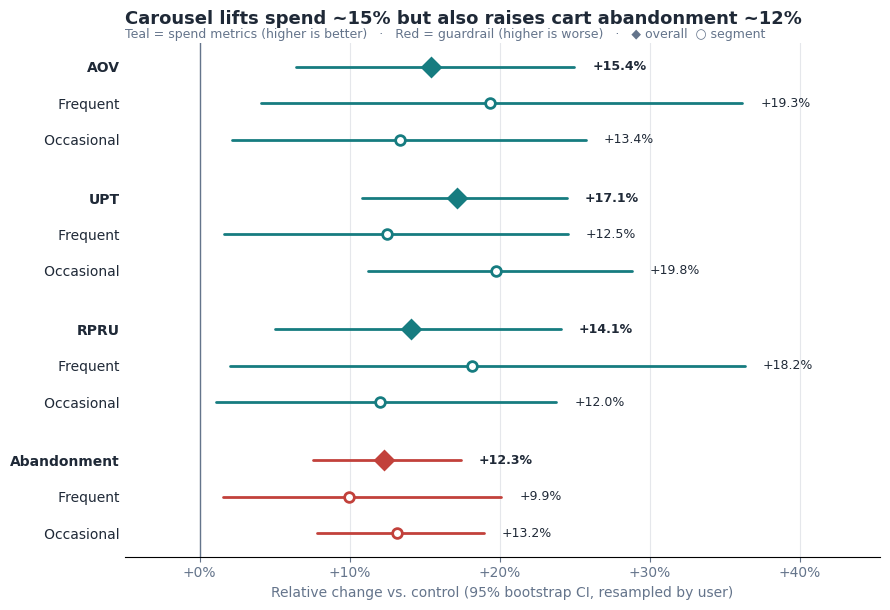

In [16]:
# Summary chart: relative lift vs. control with 95% CI (also used in the README)
SPEND, GUARD, INK, MUTED, GRID = '#167C80', '#C2413B', '#1F2937', '#64748B', '#E5E7EB'

fig, ax = plt.subplots(figsize=(9, 6.2))
y, yticks, ylabels = 0, [], []
for metric in METRICS:
    color = GUARD if metric == 'Abandonment' else SPEND
    for _, r in lifts[lifts['metric'] == metric].iterrows():
        overall = r['segment'] == 'Overall'
        ax.plot([r['ci_low'], r['ci_high']], [y, y], color=color, lw=2, solid_capstyle='round')
        ax.plot(r['lift'], y, marker='D' if overall else 'o', ms=9 if overall else 7,
                color=color if overall else 'white', mec=color, mew=2, zorder=3)
        ax.text(r['ci_high'] + 0.012, y, f"{r['lift']:+.1%}", va='center', fontsize=9,
                color=INK, fontweight='bold' if overall else 'normal')
        yticks.append(y)
        ylabels.append(f"{metric}" if overall else f"   {r['segment']}")
        y -= 1
    y -= 0.6

ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(yticks, ylabels)
for lbl in ax.get_yticklabels():
    if not lbl.get_text().startswith(' '):
        lbl.set_fontweight('bold')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:+.0%}'))
ax.set_xlim(min(-0.05, lifts['ci_low'].min() - 0.02), lifts['ci_high'].max() + 0.09)
ax.grid(axis='x', color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0, colors=INK)
ax.tick_params(axis='x', colors=MUTED)
ax.set_xlabel('Relative change vs. control (95% bootstrap CI, resampled by user)', color=MUTED)
ax.set_title('Carousel lifts spend ~15% but also raises cart abandonment ~12%',
             loc='left', fontsize=13, fontweight='bold', color=INK, pad=14)
ax.text(0, 1.01, 'Teal = spend metrics (higher is better)   ·   Red = guardrail (higher is worse)   ·   ◆ overall  ○ segment',
        transform=ax.transAxes, fontsize=9, color=MUTED)
fig.tight_layout()
fig.savefig('../assets/lift_summary.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

## 7. Revenue impact
Revenue per **assigned** user (including users who spent $0) captures both the spend lift
and the revenue lost to extra abandonment in a single number, so the projection is net of
the guardrail cost. The 90-day experiment window is annualized and scaled to the ~200K
active-user base.

### 7.1 Full rollout (all shoppers)

In [17]:
COMPANY_USER_BASE = 200_000
annualization_factor = 365 / 90

spend_per_user = users.groupby('variant')['total_spend'].mean()
lift_per_user = (spend_per_user['treatment'] - spend_per_user['control']) * annualization_factor

t_stat, p_val = ttest_ind(users[users['variant'] == 'treatment']['total_spend'],
                          users[users['variant'] == 'control']['total_spend'], equal_var=False)

print(f'Revenue per assigned user (90 days): control ${spend_per_user["control"]:.2f}, treatment ${spend_per_user["treatment"]:.2f}  (p = {p_val:.4f})')
print(f'Net lift/user/year: ${lift_per_user:.2f}')
print(f'Projected annual incremental revenue (full rollout): ${lift_per_user * COMPANY_USER_BASE:,.2f}')

Revenue per assigned user (90 days): control $74.45, treatment $83.43  (p = 0.0094)
Net lift/user/year: $36.42
Projected annual incremental revenue (full rollout): $7,284,291.62


### 7.2 Frequent shoppers only

In [18]:
#Revenue Forecast -- Frequent Shoppers Only
# what fraction of the user base is "frequent"?
frequent_fraction = (users['segment'] == 'frequent').mean()
frequent_user_base = COMPANY_USER_BASE * frequent_fraction

print(f'Frequent shoppers: {frequent_fraction*100:.1f}% of user base')
print(f'Frequent shopper population (of {COMPANY_USER_BASE:,}): {frequent_user_base:,.0f}')

# average total spend per user, control vs treatment, frequent shoppers only
# (includes $0 for abandoners, same logic as the full-rollout forecast in 7.1)
freq_spend = users[users['segment'] == 'frequent'].groupby('variant')['total_spend'].mean()
control_freq_spend = freq_spend['control']
treatment_freq_spend = freq_spend['treatment']

# annualize and compute the lift, frequent shoppers only
baseline_freq_per_user = control_freq_spend * annualization_factor
treatment_freq_per_user = treatment_freq_spend * annualization_factor
lift_freq_per_user = treatment_freq_per_user - baseline_freq_per_user
lift_freq_pct = lift_freq_per_user / baseline_freq_per_user

# scale to only the frequent-shopper portion of the user base
#(this is the number consistent with a segment-targeted rollout,
#not the full 200K company user base)
annual_incremental_revenue_freq_only = lift_freq_per_user * frequent_user_base

print(f'Baseline (frequent) revenue/user/year: ${baseline_freq_per_user:.2f}')
print(f'Net lift/user/year (frequent only): ${lift_freq_per_user:.2f} (~{lift_freq_pct*100:.1f}%)')
print(f'Projected annual incremental revenue (frequent shoppers only): ${annual_incremental_revenue_freq_only:,.2f}')

Frequent shoppers: 20.2% of user base
Frequent shopper population (of 200,000): 40,493
Baseline (frequent) revenue/user/year: $510.15
Net lift/user/year (frequent only): $87.79 (~17.2%)
Projected annual incremental revenue (frequent shoppers only): $3,555,023.10


## 8. Executive summary

- **Result:** The carousel significantly increased AOV (+15.4%), UPT (+17.1%) and RPRU
  (+14.1%). It also significantly increased cart abandonment from 22.18% to 24.91%
  (+12.3% relative), and that holds when sessions are clustered by user.
- **Net effect:** Revenue per assigned user, which already nets out lost abandoned
  carts, rose ~12%. That projects to **~$7.3M/year** for a full rollout or **~$3.6M/year**
  for frequent shoppers only.
- **Segments:** Frequent shoppers showed a larger spend lift and a smaller abandonment
  increase than occasional shoppers. The interaction tests are **not significant**, so
  this difference is directional, not confirmed.
- **Recommendation:** Roll out in phases. Launch first to frequent shoppers, who have the
  lowest baseline abandonment and the strongest directional response. Ship a clearer
  skip/dismiss option before extending to occasional shoppers. Keep abandonment as a
  standing guardrail, and re-test the segment difference with a powered follow-up.

## Limitations
- **Synthetic data:** effects were embedded by the generator, so the analysis demonstrates
  method rather than a real-world finding.
- **Fixed assignment:** each user's variant is fixed at first exposure, and the analysis
  does not model novelty or fatigue from seeing the carousel repeatedly.
- **Annualization:** the projection assumes the 90-day effect persists for a full year with
  no decay. Treat it as an upper bound.
- **Exploratory segments:** segment-level results are exploratory (see 5.4–5.5).